# 配对状态 v3 的候选片段：导出、最短时长筛选、误报片段小视频

接 `20261108_KP_pair_state6d_speed.ipynb`（v3，输出 `20261108_pair_state6d_speed/`）。**这里不重跑 Infomap**：直接读 v3 保存的微状态（`02_microstates`）和"状态 → 簇"表（`03_state_clusters`，训练集的簇），按 v3 Step 5 完全相同的方法重算每帧分数（训练集拟合 P(类别 | 簇)、平滑、训练集上取 F1 最大的阈值）。

2026-11-08 讨论后要做的三件事：

1. **候选片段表**：测试视频（K_1_3、P_1_3）里每一段"分数超过阈值"的连续帧 = 一个候选片段。FM 看 qc（FM1、FM2 两对），MM 看 att（M1M2）。每段给出起止帧、时间、分数，以及和 BORIS 的重叠：命中（碰到标注的类别）、误报（只碰到 `none` 或别的已知类别）、只落在 `unknown` 上（如 P 组的 follow，不计入精确率）。同时给出 BORIS 原始行为名，方便判断误报到底是什么行为。
2. **最短时长筛选**：最短时长 = 训练视频中该类别 BORIS bout 时长的**第 5 百分位**（只用训练集，测试集不参与定这个数）。候选片段短于它的去掉。筛选前后的结果都报告。
3. **误报片段小视频**：P_1_3 的 FM2（导致 FM1/FM2 比例判反的那一对），qc，τ 用**只看训练集的规则**选（v3 Step 3a 留一实验交叉验证 qc AUC 最高的 τ），不按测试结果挑。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261108_pair_state6d_candidates/`（v3 的目录只读，不改）。

## 参数

前半部分必须和 v3 一致（用来找到 v3 的文件并按同样方法打分；Setup 会和 v3 的 `params.json` 核对）。后半部分是本 notebook 的新参数。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261108_pair_state6d_candidates_v3"
SOURCE_RUN = "20261108_pair_state6d_speed_v3"   # v3 run: microstates and state -> cluster tables are reused (read only)
OUTPUT_ROOT = None    # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
FPS_NOMINAL = 166.0
DPI = 200
THUMB_WIDTH = 900

# --- must equal v3 (checked against its params.json)
HEAD_PEC_MAX_MM = None
SPEED_HALF_WINDOW = 3
D_EDGES_MM = [0, 5, 10, 15, 20, 30, 40]
D_OVERFLOW = True
N_BINS_DZ = 4
N_BINS_THETA = 8
SPEED_QUANTILES = [0.5, 0.9]
CONTACT_STATE = True
MIN_STATE_VISITS = 0
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
DURATION_S = {"qc": (0.75, 4.0), "att": (5 / FPS_NOMINAL, 0.75), "wrap": (0.75, None)}
SMOOTH_FRAMES = {c: max(1, int(round(lo * FPS_NOMINAL))) for c, (lo, _hi) in DURATION_S.items()}
PRIOR_FRAMES = 50.0

# --- this notebook
TAUS = {"FM": [3, 7, 17, 30, 50], "MM": [3, 7, 14, 17]}   # the taus v3 analysed in full
TARGETS = {"FM": ("qc", ["FM1", "FM2"]), "MM": ("att", ["M1M2"])}   # class and listed pairs per unit (M2M1 = M1M2)
MIN_DUR_QUANTILE = 0.05   # minimum candidate length = this quantile of train BORIS bout lengths (user choice 2026-11-08)

# --- clips (Step 4)
CLIP_EXPERIMENT = "20260112_P_1_3_FCMC"
CLIP_PAIR = "FM2"
CLIP_CLASS = "qc"
CLIP_TAU = None           # None -> train-only rule: v3 Step 3a best LOEO-AUC tau for CLIP_CLASS
CLIP_VERDICTS = ["false", "unknown_only"]   # which candidates get a clip
CLIP_PAD_S = 1.0          # seconds of context before and after the candidate
CLIP_STEP = 2             # write every 2nd frame ...
CLIP_FPS = 41.5           # ... at 41.5 fps -> half speed (166 fps source)
CLIP_CROP = 300           # proxy pixels (800 px frame) cropped around the pair
CLIP_SIZE = 600           # output size of the crop
MAX_CLIPS = 60

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}; source {SOURCE_RUN}; smoothing frames {SMOOTH_FRAMES}")

36 parameters; run 20261108_pair_state6d_candidates; source 20261108_pair_state6d_speed; smoothing frames {'qc': 124, 'att': 5, 'wrap': 124}


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、打开 v3 的输出目录（只读）和本 notebook 的输出目录，核对参数和 v3 一致，定义打分函数（和 v3 Step 5 相同）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib
import subprocess

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cv2
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis import behavior_features as BF
from scripts.analysis.behavior_dataset import resolve_roots, find_package
from scripts.review.ledger import EVENT_COLUMNS, read_csv, static_labels, swap_list, owner_series
from scripts.review.review_gui import ProxyVideo, proxy_fps
from scripts.review.proxies import find_ffmpeg

importlib.reload(P4)

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
SRC = S.RunLayout(OUT_ROOT / SOURCE_RUN, dpi=DPI, thumb_width=THUMB_WIDTH)   # read only
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
CLIPS = L.root / "clips"
CLIPS.mkdir(exist_ok=True)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}


def _allow_listed(experiment, final):
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed

# parameters shared with v3 must be identical
_src_params = json.loads(SRC.params_json.read_text(encoding="utf-8"))["parameters"]
_shared = ["TRAIN_EXPERIMENTS", "TEST_EXPERIMENTS", "UNITS", "HEAD_PEC_MAX_MM", "SPEED_HALF_WINDOW", "D_EDGES_MM",
           "D_OVERFLOW", "N_BINS_DZ", "N_BINS_THETA", "SPEED_QUANTILES", "CONTACT_STATE", "MIN_STATE_VISITS",
           "LABEL_CLASSES", "DURATION_S", "SMOOTH_FRAMES", "PRIOR_FRAMES"]
_norm = lambda v: json.dumps(v, sort_keys=True, default=str)
_diff = [k for k in _shared if _norm(json.loads(_norm(PARAMETERS[k]))) != _norm(_src_params.get(k))]
if _diff:
    raise ValueError(f"parameters differ from {SOURCE_RUN}: {_diff}")

L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "source_run": str(SRC.root), "date": time.strftime("%Y-%m-%d %H:%M:%S"),
                        "output_dir": str(L.root), "review_root": str(REVIEW_ROOT), "paths_config": str(_CONFIG),
                        "platform": platform.platform()})

PRE = {"hpmax": HEAD_PEC_MAX_MM, "sph": SPEED_HALF_WINDOW}
STATE_P = {"dmax": D_EDGES_MM[-1], "bd": len(D_EDGES_MM) - 1, "of": bool(D_OVERFLOW),
           "bz": N_BINS_DZ, "bth": N_BINS_THETA, "bs": len(SPEED_QUANTILES) + 1, "ct": bool(CONTACT_STATE),
           "minv": MIN_STATE_VISITS}


def tau_p(tau):
    return {"tau": int(tau), **STATE_P}


def copy_name(a, b):
    return f"{a}{b}"


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
CLASS_COLOR = {"wrap": "#d62728", "qc": "#ff7f0e", "att": "#7f3c8d", "unknown": "#c7c7c7", "none": "#ffffff"}
VERDICT_COLOR = {"hit": "#2e8b3e", "false": "#d62728", "unknown_only": "#8c8c8c"}


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def load_exp(e):
    return SRC.load_npz("00", "pairvars", "all", PRE, exp_short(e))


def load_micro(unit, set_name):
    return SRC.load_npz("02", "microstates", unit, STATE_P, set_name)


def blocks_of(mic):
    return mic["exp"].astype(np.int64) * 10 + mic["copy"].astype(np.int64)


def train_clusters(unit, tau):
    # state -> train cluster (-1 = state outside the graph), from v3 Step 3
    tab = SRC.load_csv("03", "state_clusters", unit, tau_p(tau), "train")
    return tab.sort_values("state")["cluster"].to_numpy(np.int64)


def scoring_ids(lab, st):
    # as v3: frames without a state -> one extra pseudo-cluster id k
    k = int(lab.max()) + 1
    fc = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
    return P4.with_nostate_cluster(fc, st >= 0, k), k + 1


def fit_and_score(ids_tr, n_ids, ids_te, ytr, b_tr, b_te, w):
    # v3 Step 5: train-fitted P(class | cluster), centred smoothing, best-F1 threshold on train
    sc = P4.cluster_scores(ids_tr, ytr, n_ids, PRIOR_FRAMES)
    ok = (ytr >= 0) & (ids_tr >= 0)
    base = float(ytr[ok].mean()) if ok.any() else 0.0
    sm_tr = P4.rolling_mean_blocks(P4.frame_scores(ids_tr, sc, base), b_tr, w)
    sm_te = P4.rolling_mean_blocks(P4.frame_scores(ids_te, sc, base), b_te, w)
    thr, _f1 = P4.best_f1_threshold(sm_tr, ytr)
    return sm_te, thr


def runs_in_blocks(mask, block):
    # (start, end) index pairs of runs of True that never cross a block boundary
    mask = np.asarray(mask, dtype=bool)
    brk = np.ones(len(mask), dtype=bool)
    brk[1:] = (mask[1:] != mask[:-1]) | (np.asarray(block)[1:] != np.asarray(block)[:-1])
    starts = np.flatnonzero(brk)
    ends = np.concatenate([starts[1:], [len(mask)]])
    return [(int(a), int(b)) for a, b in zip(starts, ends) if mask[a]]


def drop_short(pred, block, min_len):
    out = np.zeros(len(pred), dtype=bool)
    for a, b in runs_in_blocks(pred, block):
        if b - a >= min_len:
            out[a:b] = True
    return out


def mmss(seconds):
    return f"{int(seconds // 60):02d}:{seconds % 60:05.2f}"


print("source", SRC.root)
print("output", L.root)

source \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state6d_speed
output \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state6d_candidates


## Step 1 — 读 v3 的微状态、簇、BORIS 标注；重算每帧分数

**做什么**：读 v3 的 `02_microstates`（训练、测试）和每个 τ 的 `03_state_clusters`（训练集簇）。BORIS 标注按 v3 Step 2b 的规则重新生成（qc / att / wrap，其余 `unknown`，没有 bout = `none`）。每个单元、每个 τ，对目标类别（FM：qc；MM：att）用训练集拟合簇分数、平滑、定阈值，再给测试帧打分。

**核对**：重算的阈值必须和 v3 `05_detection` 里的阈值一致（打印最大差值），否则说明没有复现 v3。

**输出**：只在内存里（后面几步用）。

In [3]:
# Step 1: reload v3 microstates and clusters, BORIS labels, recompute frame scores.
L.clear_log("01")
FRAME_LABELS, BOUTS = {}, {}
for e in ALL_EXPERIMENTS:
    BOUTS[e] = M.bouts_of(e)
    frames = load_exp(e)["frames"]
    for cp, (a, b) in COPY_PAIR.items():
        FRAME_LABELS[(e, cp)] = P4.pair_frame_labels(BOUTS[e], a, b, frames, LABEL_CLASSES, directed=True)


def labels_for(mic):
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            out[(mic["exp"] == ei) & (mic["copy"] == ci)] = FRAME_LABELS[(e, cp)]
    return out


MIC = {(u, s): load_micro(u, s) for u in UNITS for s in SETS}
YLAB = {(u, s): labels_for(MIC[(u, s)]) for u in UNITS for s in SETS}
FPS = {e: float(load_exp(e)["fps"]) for e in ALL_EXPERIMENTS}
SCORE = {}   # (unit, tau) -> (smoothed test score, threshold)
det = SRC.load_csv("05", "detection", "all", STATE_P, "test")
check = []
for unit in UNITS:
    c = TARGETS[unit][0]
    tr, te = MIC[(unit, "train")], MIC[(unit, "test")]
    ytr = P4.detection_target(YLAB[(unit, "train")], c)
    st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
    for tau in TAUS[unit]:
        lab = train_clusters(unit, tau)
        ids_tr, n_ids = scoring_ids(lab, st_tr)
        ids_te, _ = scoring_ids(lab, st_te)
        sm_te, thr = fit_and_score(ids_tr, n_ids, ids_te, ytr, blocks_of(tr), blocks_of(te), SMOOTH_FRAMES[c])
        SCORE[(unit, tau)] = (sm_te, thr)
        v3 = det[(det["unit"] == unit) & (det["class"] == c) & (det["method"] == "clusters") & (det["tau"] == tau)]
        check.append({"unit": unit, "class": c, "tau": tau, "threshold": thr,
                      "threshold_v3": float(v3["threshold"].iloc[0]),
                      "abs_diff": abs(thr - float(v3["threshold"].iloc[0]))})
CHECK = pd.DataFrame(check)
print(CHECK.to_string(index=False))
if CHECK["abs_diff"].max() > 1e-9:
    raise RuntimeError("thresholds differ from v3: the scores were not reproduced")
print("v3 thresholds reproduced")
L.log("01", "done")

unit class  tau  threshold  threshold_v3     abs_diff
  FM    qc    3   0.152855      0.152855 2.775558e-17
  FM    qc    7   0.149157      0.149157 2.775558e-17
  FM    qc   17   0.145933      0.145933 5.551115e-17
  FM    qc   30   0.135340      0.135340 5.551115e-17
  FM    qc   50   0.117072      0.117072 8.326673e-17
  MM   att    3   0.045837      0.045837 1.387779e-17
  MM   att    7   0.046359      0.046359 0.000000e+00
  MM   att   14   0.037439      0.037439 0.000000e+00
  MM   att   17   0.034352      0.034352 5.551115e-17
v3 thresholds reproduced


## Step 2 — 最短时长 = 训练集 BORIS bout 时长的第 5 百分位

**做什么**：在 4 个训练视频里，取目标类别（qc：FM1、FM2；att：M1M2）每个 BORIS bout 的长度（帧），算第 `MIN_DUR_QUANTILE` 分位数作为最短时长。测试视频不参与。

**图** `02_bout_lengths`：训练集 bout 长度的分布（对数横轴）。黑色虚线 = 第 5 百分位（最短时长）；灰色点线 = 平滑窗口（v3 的时长下限，你估计的值）。

**输出**：`data/02_min_duration__all__q5__train.csv`。

  fig figures/02_bout_lengths__all__q5__train.png


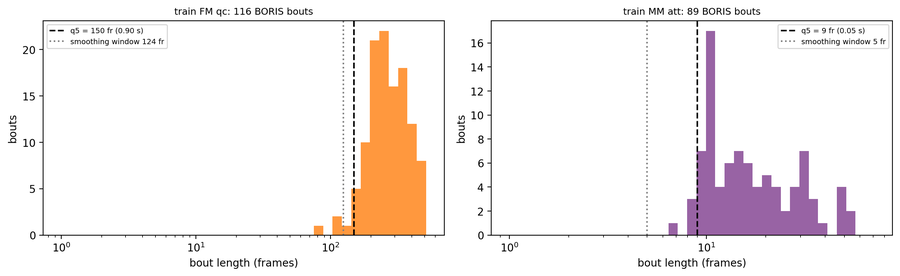

  csv data/02_min_duration__all__q5__train.csv  rows 2
unit class  train_bouts  quantile  min_duration_frames  min_duration_s  median_bout_s  smoothing_frames
  FM    qc          116      0.05                  149           0.898          1.557               124
  MM   att           89      0.05                    9           0.054          0.090                 5


In [4]:
# Step 2: minimum candidate length from train BORIS bouts.
L.clear_log("02")
MIN_DUR, rows = {}, []
fig, axes = plt.subplots(1, len(UNITS), figsize=(6 * len(UNITS), 3.8), squeeze=False)
for ax, unit in zip(axes[0], UNITS):
    c, pairs = TARGETS[unit]
    lengths = []
    for e in TRAIN_EXPERIMENTS:
        for cp in pairs:
            a0, a1 = S.bool_runs(P4.base_class(FRAME_LABELS[(e, cp)]) == c)
            lengths += list(a1 - a0)
    lengths = np.asarray(lengths)
    q = float(np.quantile(lengths, MIN_DUR_QUANTILE))
    MIN_DUR[c] = int(np.floor(q))
    rows.append({"unit": unit, "class": c, "train_bouts": len(lengths), "quantile": MIN_DUR_QUANTILE,
                 "min_duration_frames": MIN_DUR[c], "min_duration_s": MIN_DUR[c] / FPS_NOMINAL,
                 "median_bout_s": float(np.median(lengths)) / FPS_NOMINAL,
                 "smoothing_frames": SMOOTH_FRAMES[c]})
    bins = np.logspace(0, np.log10(max(lengths.max(), 10)), 40)
    ax.hist(lengths, bins=bins, color=CLASS_COLOR[c], alpha=0.8)
    ax.axvline(q, color="k", ls="--", label=f"q{int(100 * MIN_DUR_QUANTILE)} = {q:.0f} fr ({q / FPS_NOMINAL:.2f} s)")
    ax.axvline(SMOOTH_FRAMES[c], color="0.5", ls=":", label=f"smoothing window {SMOOTH_FRAMES[c]} fr")
    ax.set_xscale("log")
    ax.set_xlabel("bout length (frames)")
    ax.set_ylabel("bouts")
    ax.set_title(f"train {unit} {c}: {len(lengths)} BORIS bouts", fontsize=9)
    ax.legend(fontsize=7)
fig.tight_layout()
_fp = L.save_fig(fig, "02", "bout_lengths", "all", {"q": int(100 * MIN_DUR_QUANTILE)}, "train")
display(IPImage(filename=str(L.thumbs / _fp.name)))
MIN_T = pd.DataFrame(rows)
L.save_csv(MIN_T, "02", "min_duration", "all", {"q": int(100 * MIN_DUR_QUANTILE)}, "train")
print(MIN_T.round(3).to_string(index=False))
L.log("02", "done")

## Step 3 — 每个测试视频：筛选前后的结果；候选片段表；BORIS bout 表

**做什么**：
1. 每个单元 × τ × 测试视频 × 配对：阈值下的候选帧，筛选前（`filter = none`）和去掉短于最短时长的片段后（`filter = min_dur`）。指标同 v3 Step 5b：精确率、召回率、bout 检出（一个 BORIS bout 至少一半帧被选中算检出）、报警片段中真的数量、每分钟误报片段数。`unknown` 帧不计入精确率。
2. **候选片段表**：每段候选一行。`verdict`：`hit` = 碰到至少一帧目标类别；`false` = 没碰到目标类别，但碰到 `none` 或其他已知类别；`unknown_only` = 只落在 `unknown` 帧上（不计入精确率）。`boris_behaviours` = 这段时间内这对鱼的 BORIS 原始行为及重叠帧数（任何方向）。`passes_min_dur` = 长度是否不短于最短时长。
3. **BORIS bout 表**：测试视频中每个目标类别的 bout，被候选覆盖的比例（筛选前后）和是否检出，用来看漏掉的是哪些。
4. **FM1 / FM2 比例**：每个测试视频预测的 qc 帧数 FM1 : FM2 和真实比例，看方向是否一致。

**输出**：`data/03_per_video__all__…__test.csv`、`data/03_candidates__all__…__test.csv`、`data/03_boris_bouts__all__…__test.csv`、`data/03_fm_ratio__all__…__test.csv`。

In [5]:
# Step 3: per-video metrics with and without the minimum length; candidate and BORIS bout tables.
L.clear_log("03")


def metrics(y, pred, block, minutes):
    tp = int((pred & (y == 1)).sum())
    n_pred = int((pred & (y >= 0)).sum())
    found, total = P4.bout_recall(y, pred, block)
    good, counted = P4.bout_precision(y, pred, block)
    return {"true_frames": int((y == 1).sum()), "pred_frames": n_pred, "precision": tp / max(n_pred, 1),
            "recall": tp / max(int((y == 1).sum()), 1), "bouts_found": found, "bouts": total,
            "pred_bouts_correct": good, "pred_bouts": counted,
            "wrong_pred_bouts_per_min": (counted - good) / max(minutes, 1e-9)}


def behaviour_overlap(e, a, b, f0, f1):
    # BORIS behaviours of pair {a, b} (any direction) overlapping source frames [f0, f1]
    out = {}
    for r in BOUTS[e].itertuples():
        who = str(r.who)
        sep = "<->" if "<->" in who else ("->" if "->" in who else None)
        if sep is None or {s.strip() for s in who.split(sep)} != {a, b}:
            continue
        n = min(int(r.end), f1) - max(int(r.start), f0) + 1
        if n > 0:
            out[str(r.behavior)] = out.get(str(r.behavior), 0) + n
    return "; ".join(f"{k}:{v}" for k, v in sorted(out.items(), key=lambda kv: -kv[1]))


VID, CAND, BB, RATIO = [], [], [], []
PRED = {}   # (unit, tau, exp, pair) -> (pred, pred filtered, y, frames, score, thr)
for unit in UNITS:
    c, pairs = TARGETS[unit]
    te = MIC[(unit, "test")]
    y_all = P4.detection_target(YLAB[(unit, "test")], c)
    lab_all = P4.base_class(YLAB[(unit, "test")])
    exp_names = [str(x) for x in te["exp_names"]]
    copy_names = [str(x) for x in te["copy_names"]]
    for tau in TAUS[unit]:
        sm, thr = SCORE[(unit, tau)]
        for ei, e in enumerate(exp_names):
            for cp in pairs:
                m = (te["exp"] == ei) & (te["copy"] == copy_names.index(cp))
                y, s, fr = y_all[m], sm[m], te["frame"][m]
                blk = np.zeros(len(y))
                pred = s >= thr
                pred_f = drop_short(pred, blk, MIN_DUR[c])
                PRED[(unit, tau, e, cp)] = (pred, pred_f, y, fr, s, thr, lab_all[m])
                minutes = len(y) / FPS[e] / 60.0
                for name, p in (("none", pred), ("min_dur", pred_f)):
                    VID.append({"unit": unit, "class": c, "tau": tau, "experiment": exp_short(e), "pair": cp,
                                "filter": name, **metrics(y, p, blk, minutes)})
                a, b = COPY_PAIR[cp]
                for k, (i0, i1) in enumerate(runs_in_blocks(pred, blk)):
                    seg = y[i0:i1]
                    verdict = "hit" if (seg == 1).any() else ("false" if (seg == 0).any() else "unknown_only")
                    f0, f1 = int(fr[i0]), int(fr[i1 - 1])
                    CAND.append({"unit": unit, "class": c, "tau": tau, "experiment": exp_short(e), "pair": cp,
                                 "candidate": k, "start_frame": f0, "end_frame": f1, "frames": i1 - i0,
                                 "start_s": f0 / FPS[e], "end_s": f1 / FPS[e], "duration_s": (i1 - i0) / FPS[e],
                                 "start_mmss": mmss(f0 / FPS[e]), "passes_min_dur": (i1 - i0) >= MIN_DUR[c],
                                 "verdict": verdict, "n_frames_target": int((seg == 1).sum()),
                                 "n_frames_none_or_other": int((seg == 0).sum()), "n_frames_unknown": int((seg == -1).sum()),
                                 "peak_score": float(np.nanmax(s[i0:i1])), "mean_score": float(np.nanmean(s[i0:i1])),
                                 "threshold": thr, "boris_behaviours": behaviour_overlap(e, a, b, f0, f1)})
                for k, (i0, i1) in enumerate(runs_in_blocks(y == 1, blk)):
                    BB.append({"unit": unit, "class": c, "tau": tau, "experiment": exp_short(e), "pair": cp, "bout": k,
                               "start_frame": int(fr[i0]), "end_frame": int(fr[i1 - 1]), "duration_s": (i1 - i0) / FPS[e],
                               "start_mmss": mmss(fr[i0] / FPS[e]),
                               "covered": float(pred[i0:i1].mean()), "covered_min_dur": float(pred_f[i0:i1].mean()),
                               "found": bool(pred[i0:i1].mean() >= 0.5), "found_min_dur": bool(pred_f[i0:i1].mean() >= 0.5),
                               "peak_score": float(np.nanmax(s[i0:i1])), "threshold": thr})
VID_T, CAND_T, BB_T = pd.DataFrame(VID), pd.DataFrame(CAND), pd.DataFrame(BB)
for unit in UNITS:
    if TARGETS[unit][1] != ["FM1", "FM2"]:
        continue
    for tau in TAUS[unit]:
        for e in TEST_EXPERIMENTS:
            r = {"unit": unit, "tau": tau, "experiment": exp_short(e)}
            for name, j in (("none", 0), ("min_dur", 1)):
                p1, y1 = PRED[(unit, tau, e, "FM1")][j], PRED[(unit, tau, e, "FM1")][2]
                p2, y2 = PRED[(unit, tau, e, "FM2")][j], PRED[(unit, tau, e, "FM2")][2]
                r.update({"true_FM1": int((y1 == 1).sum()), "true_FM2": int((y2 == 1).sum()),
                          f"pred_FM1_{name}": int(p1.sum()), f"pred_FM2_{name}": int(p2.sum())})
            r["true_more"] = "FM1" if r["true_FM1"] > r["true_FM2"] else "FM2"
            for name in ("none", "min_dur"):
                r[f"pred_more_{name}"] = "FM1" if r[f"pred_FM1_{name}"] > r[f"pred_FM2_{name}"] else "FM2"
                r[f"direction_ok_{name}"] = r[f"pred_more_{name}"] == r["true_more"]
            RATIO.append(r)
RATIO_T = pd.DataFrame(RATIO)
for t, nm in ((VID_T, "per_video"), (CAND_T, "candidates"), (BB_T, "boris_bouts"), (RATIO_T, "fm_ratio")):
    L.save_csv(t, "03", nm, "all", STATE_P, "test")

show = ["unit", "tau", "experiment", "pair", "filter", "true_frames", "pred_frames", "precision", "recall",
        "bouts_found", "bouts", "pred_bouts_correct", "pred_bouts", "wrong_pred_bouts_per_min"]
print(VID_T[show].round(3).to_string(index=False))
print()
print(RATIO_T.to_string(index=False))
print()
print(CAND_T.groupby(["unit", "tau", "experiment", "pair", "verdict"]).size().unstack(fill_value=0).to_string())
L.log("03", "done")

  csv data/03_per_video__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv  rows 56
  csv data/03_candidates__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv  rows 2313
  csv data/03_boris_bouts__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv  rows 546
  csv data/03_fm_ratio__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv  rows 10
unit  tau experiment pair  filter  true_frames  pred_frames  precision  recall  bouts_found  bouts  pred_bouts_correct  pred_bouts  wrong_pred_bouts_per_min
  FM    3      K_1_3  FM1    none          827         2427      0.284   0.834            4      4                   4          15                     0.314
  FM    3      K_1_3  FM1 min_dur          827         2047      0.337   0.834            4      4                   4           9                     0.143
  FM    3      K_1_3  FM2    none        11938         9904      0.513   0.426           21     44                  38          82                     1.257
  FM    3      K_1_3  FM2 m

## Step 4 — 全片时间轴：分数、阈值、BORIS、候选片段

**做什么**：画 `CLIP_EXPERIMENT` 的 `CLIP_PAIR`（默认 P_1_3 的 FM2）整段视频的分数，以及作为对照的同一视频另一对（FM1）。τ = `CLIP_TAU`（`None` 时用 v3 Step 3a 只看训练集选出的 qc 最佳 τ）。

**图** `04_timeline`：每对鱼一行，横轴 = 分钟。黑线 = 平滑分数；黑色虚线 = 阈值；底部色带 = BORIS（橙 = qc，灰 = unknown，白 = none）；顶部短条 = 候选片段（绿 = 命中，红 = 误报，灰 = 只落在 unknown 上；细条 = 短于最短时长）。

clip tau = 30 (FM, train-only rule)


  fig figures/04_timeline__FM__tau30-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__P_1_3.png


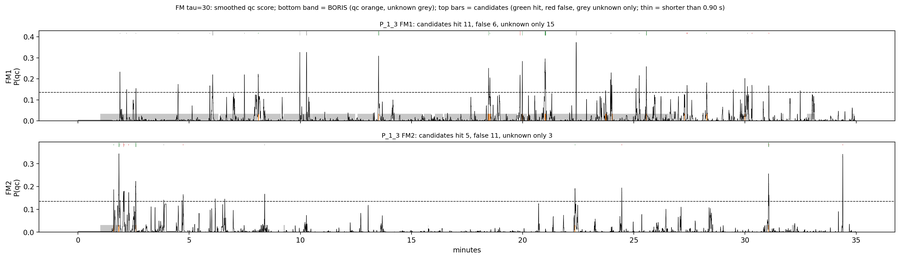

In [6]:
# Step 4: whole-video timeline for the clip experiment.
L.clear_log("04")
if CLIP_TAU is None:
    _tc = SRC.load_csv("03a", "tau_choice", "all", STATE_P, "train")
    _unit = [u for u in UNITS if TARGETS[u][0] == CLIP_CLASS][0]
    CLIP_TAU = int(_tc[(_tc["unit"] == _unit) & (_tc["reason"] == f"best_loeo_auc_{CLIP_CLASS}")]["tau"].iloc[0])
CLIP_UNIT = [u for u in UNITS if TARGETS[u][0] == CLIP_CLASS][0]
print(f"clip tau = {CLIP_TAU} ({CLIP_UNIT}, train-only rule)")
pairs = TARGETS[CLIP_UNIT][1]
fig, axes = plt.subplots(len(pairs), 1, figsize=(18, 2.6 * len(pairs)), sharex=True, squeeze=False)
for ax, cp in zip(axes[:, 0], pairs):
    pred, pred_f, y, fr, s, thr, lab = PRED[(CLIP_UNIT, CLIP_TAU, CLIP_EXPERIMENT, cp)]
    t = fr / FPS[CLIP_EXPERIMENT] / 60.0
    top = max(float(np.nanmax(s)), thr) * 1.15
    for name, col in (("unknown", CLASS_COLOR["unknown"]), (CLIP_CLASS, CLASS_COLOR[CLIP_CLASS])):
        for i0, i1 in runs_in_blocks(lab == name, np.zeros(len(lab))):
            ax.axvspan(t[i0], t[i1 - 1], ymin=0, ymax=0.08, color=col, lw=0)
    ax.plot(t, s, color="k", lw=0.5)
    ax.axhline(thr, color="k", ls="--", lw=0.8)
    cand = CAND_T[(CAND_T["tau"] == CLIP_TAU) & (CAND_T["experiment"] == exp_short(CLIP_EXPERIMENT)) & (CAND_T["pair"] == cp)]
    for r in cand.itertuples():
        ax.plot([r.start_s / 60, r.end_s / 60], [top * 0.97] * 2, color=VERDICT_COLOR[r.verdict],
                lw=6 if r.passes_min_dur else 2, solid_capstyle="butt")
    ax.set_ylim(0, top)
    ax.set_ylabel(f"{cp}\nP({CLIP_CLASS})")
    n = cand["verdict"].value_counts()
    ax.set_title(f"{exp_short(CLIP_EXPERIMENT)} {cp}: candidates hit {n.get('hit', 0)}, false {n.get('false', 0)}, "
                 f"unknown only {n.get('unknown_only', 0)}", fontsize=9)
axes[-1, 0].set_xlabel("minutes")
fig.suptitle(f"{CLIP_UNIT} tau={CLIP_TAU}: smoothed {CLIP_CLASS} score; bottom band = BORIS ({CLIP_CLASS} orange, "
             f"unknown grey); top bars = candidates (green hit, red false, grey unknown only; thin = shorter than "
             f"{MIN_DUR[CLIP_CLASS] / FPS_NOMINAL:.2f} s)", fontsize=9)
fig.tight_layout()
_p = {"tau": CLIP_TAU, **STATE_P}
_fp = L.save_fig(fig, "04", "timeline", CLIP_UNIT, _p, exp_short(CLIP_EXPERIMENT))
display(IPImage(filename=str(L.thumbs / _fp.name)))
L.log("04", "done")

## Step 5 — 误报片段小视频

**做什么**：对 `CLIP_EXPERIMENT` 的 `CLIP_PAIR`、类别 `CLIP_CLASS`、τ = `CLIP_TAU`，`verdict` 属于 `CLIP_VERDICTS`（默认：误报和只落在 unknown 上的）的每段候选，从顶视角代理视频（`proxy/top_cam.full.mp4`，800 px，166 fps，逐帧准确读取）截出前后各多 `CLIP_PAD_S` 秒的片段。

**画面**：
- 主画面 = 围绕这对鱼放大的区域（红圈 F，绿圈 = 配对里的雄鱼，蓝圈 = 另一条雄鱼；位置 = 审核后 3D 坐标投到顶视角）。
- 右上角小图 = 整个鱼缸，黄框 = 放大区域。
- 顶部文字 = 编号、判定、时间（帧号、分:秒）、分数 / 阈值、BORIS 当前帧的标注。
- 候选片段内的帧加红色边框。
- 底部条 = 这段时间的分数曲线（白）、阈值（黄虚线）、BORIS 色带（橙 = qc，灰 = unknown），竖线 = 当前帧。

**播放速度**：每 `CLIP_STEP` 帧写一帧，`CLIP_FPS` fps → 半速。

**输出**：`clips/<视频>_<配对>_<类别>_tau<τ>_<编号>_<判定>_<分:秒>.mp4`（每段一个文件），以及把所有片段按时间顺序连起来的 `..._all.mp4`；`data/05_clips__…csv` = 文件名与候选片段的对应表。

In [7]:
# Step 5: clips of the selected candidates from the full-rate top-view proxy.
L.clear_log("05")
try:
    FFMPEG = find_ffmpeg()
except RuntimeError:
    FFMPEG = None   # clips stay mp4v (no h264 re-encode, no combined file)


def named_top2d(e):
    # (frames, 3, 2) top-view pixel positions (source 1200 px) of F, M1, M2 from the reviewed 3D tracks
    pkg = find_package(REVIEW_ROOT, e)
    with np.load(pkg / "review_data.npz") as z:
        frames = np.asarray(z["frames"], int)
        fish_ids = [str(f) for f in z["fish_ids"]]
        pj = np.asarray(z["proj2d"][:, :, 0, :], float)   # view 0 = top_cam
    ev = read_csv(pkg / "id_pass" / "human_events.csv", EVENT_COLUMNS)
    owner = owner_series(len(fish_ids), swap_list(ev, fish_ids), frames)
    tmp = np.zeros((len(frames), 3, 1, 3))
    tmp[:, :, 0, :2] = pj
    named, _valid = BF.named_nodes(tmp, owner, fish_ids, static_labels(ev, fish_ids))
    manifest = json.loads((pkg.parent / "proxy" / "proxy_manifest.json").read_text(encoding="utf-8"))
    return frames, named[:, :, 0, :2], pkg.parent / "proxy" / "top_cam.full.mp4", manifest


def to_h264(src, dst):
    if FFMPEG is None:
        src.replace(dst)
        return
    subprocess.run([FFMPEG, "-y", "-loglevel", "error", "-i", str(src), "-c:v", "libx264", "-crf", "20",
                    "-pix_fmt", "yuv420p", str(dst)], check=True)
    src.unlink()


cand = CAND_T[(CAND_T["unit"] == CLIP_UNIT) & (CAND_T["tau"] == CLIP_TAU) & (CAND_T["experiment"] == exp_short(CLIP_EXPERIMENT))
              & (CAND_T["pair"] == CLIP_PAIR) & (CAND_T["verdict"].isin(CLIP_VERDICTS))].sort_values("start_frame").head(MAX_CLIPS)
pred, pred_f, y, fr, s, thr, lab = PRED[(CLIP_UNIT, CLIP_TAU, CLIP_EXPERIMENT, CLIP_PAIR)]
frames_pkg, top2d, proxy_path, manifest = named_top2d(CLIP_EXPERIMENT)
src_w = float(manifest["views"]["top_cam"]["source_width"])
video = ProxyVideo(proxy_path, fps=proxy_fps(manifest, "top_cam", False))
fps_e = FPS[CLIP_EXPERIMENT]
a_name, b_name = COPY_PAIR[CLIP_PAIR]
other = [n for n in ("F", "M1", "M2") if n not in (a_name, b_name)][0]
FISH_COL = {a_name: (40, 40, 230), b_name: (60, 200, 60), other: (230, 120, 40)}   # BGR
NAME_IDX = {"F": 0, "M1": 1, "M2": 2}
OFF = int(frames_pkg[0])   # top2d row = source frame - OFF; proxy index = source frame
pad = int(round(CLIP_PAD_S * fps_e))
STRIP_H, BANNER_H = 70, 64
clip_rows, all_parts = [], []
for n, r in enumerate(cand.itertuples()):
    f_lo, f_hi = max(int(r.start_frame) - pad, int(fr[0])), min(int(r.end_frame) + pad, int(fr[-1]))
    idx = np.arange(f_lo, f_hi + 1) - int(fr[0])
    sw, lw = s[idx], lab[idx]
    # crop centre = pair midpoint, smoothed; held where coordinates are missing
    mid = np.nanmean(top2d[f_lo - OFF:f_hi + 1 - OFF][:, [NAME_IDX[a_name], NAME_IDX[b_name]]], axis=1)
    mid = pd.DataFrame(mid).interpolate(limit_direction="both").rolling(31, center=True, min_periods=1).mean().to_numpy()
    if not np.isfinite(mid).all():
        mid = np.full_like(mid, src_w / 2)
    stem = f"{exp_short(CLIP_EXPERIMENT)}_{CLIP_PAIR}_{CLIP_CLASS}_tau{CLIP_TAU}_{n:02d}_{r.verdict}_{r.start_mmss.replace(':', 'm')}s"
    tmp_path, out_path = CLIPS / f"{stem}.tmp.mp4", CLIPS / f"{stem}.mp4"
    W = CLIP_SIZE
    writer = cv2.VideoWriter(str(tmp_path), cv2.VideoWriter_fourcc(*"mp4v"), CLIP_FPS, (W, W + BANNER_H + STRIP_H))
    smax = max(float(np.nanmax(sw)), thr) * 1.1
    for j in range(0, len(idx), CLIP_STEP):
        f = f_lo + j
        img = video.get(f)
        if img is None:
            break
        sc = img.shape[1] / src_w
        cx, cy = mid[j] * sc
        half = CLIP_CROP // 2
        x0 = int(np.clip(cx - half, 0, img.shape[1] - CLIP_CROP))
        y0 = int(np.clip(cy - half, 0, img.shape[0] - CLIP_CROP))
        crop = img[y0:y0 + CLIP_CROP, x0:x0 + CLIP_CROP].copy()
        k = W / CLIP_CROP
        crop = cv2.resize(crop, (W, W), interpolation=cv2.INTER_LINEAR)
        for nm, col in FISH_COL.items():
            p = top2d[f - OFF, NAME_IDX[nm]]
            if np.isfinite(p).all():
                u, v = (p[0] * sc - x0) * k, (p[1] * sc - y0) * k
                cv2.circle(crop, (int(u), int(v)), 16, col, 2)
                cv2.putText(crop, nm, (int(u) + 18, int(v) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
        inside = r.start_frame <= f <= r.end_frame
        if inside:
            cv2.rectangle(crop, (0, 0), (W - 1, W - 1), (0, 0, 255), 6)
        thumb = cv2.resize(img, (160, 160))
        ts = 160 / img.shape[1]
        cv2.rectangle(thumb, (int(x0 * ts), int(y0 * ts)), (int((x0 + CLIP_CROP) * ts), int((y0 + CLIP_CROP) * ts)), (0, 255, 255), 1)
        crop[6:166, W - 166:W - 6] = thumb
        banner = np.zeros((BANNER_H, W, 3), np.uint8)
        cv2.putText(banner, f"#{n} {r.verdict}  {exp_short(CLIP_EXPERIMENT)} {CLIP_PAIR} {CLIP_CLASS} tau{CLIP_TAU}  "
                    f"cand {r.start_mmss} ({r.duration_s:.2f} s)", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        cv2.putText(banner, f"frame {f}  t {mmss(f / fps_e)}  score {sw[j]:.3f} / thr {thr:.3f}  BORIS: {lw[j]}",
                    (8, 48), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255) if inside else (200, 200, 200), 1)
        strip = np.zeros((STRIP_H, W, 3), np.uint8)
        xs = np.linspace(0, W - 1, len(idx)).astype(int)
        for i0, i1 in runs_in_blocks(lw == "unknown", np.zeros(len(lw))):
            strip[STRIP_H - 10:, xs[i0]:xs[i1 - 1] + 1] = (199, 199, 199)
        for i0, i1 in runs_in_blocks(lw == CLIP_CLASS, np.zeros(len(lw))):
            strip[STRIP_H - 10:, xs[i0]:xs[i1 - 1] + 1] = (14, 127, 255)
        ys = (STRIP_H - 14 - (np.nan_to_num(sw) / smax) * (STRIP_H - 20)).astype(int)
        cv2.polylines(strip, [np.stack([xs, ys], axis=1).reshape(-1, 1, 2)], False, (255, 255, 255), 1)
        yt = int(STRIP_H - 14 - thr / smax * (STRIP_H - 20))
        for xx in range(0, W, 8):
            cv2.line(strip, (xx, yt), (min(xx + 4, W - 1), yt), (0, 255, 255), 1)
        xc = int(xs[j])
        cv2.line(strip, (xc, 0), (xc, STRIP_H - 1), (0, 0, 255), 1)
        writer.write(np.vstack([banner, crop, strip]))
    writer.release()
    to_h264(tmp_path, out_path)
    all_parts.append(out_path)
    clip_rows.append({"clip": out_path.name, "candidate": r.candidate, "verdict": r.verdict, "start_frame": r.start_frame,
                      "end_frame": r.end_frame, "start_mmss": r.start_mmss, "duration_s": r.duration_s,
                      "passes_min_dur": r.passes_min_dur, "peak_score": r.peak_score, "boris_behaviours": r.boris_behaviours})
    print(f"  {out_path.name}")
CLIP_T = pd.DataFrame(clip_rows)
L.save_csv(CLIP_T, "05", "clips", CLIP_UNIT, {"tau": CLIP_TAU, **STATE_P}, f"{exp_short(CLIP_EXPERIMENT)}_{CLIP_PAIR}")
if all_parts and FFMPEG is not None:
    lst = CLIPS / "_concat.txt"
    lst.write_text("".join(f"file '{p.as_posix()}'\n" for p in all_parts), encoding="utf-8")
    combo = CLIPS / f"{exp_short(CLIP_EXPERIMENT)}_{CLIP_PAIR}_{CLIP_CLASS}_tau{CLIP_TAU}_all.mp4"
    subprocess.run([FFMPEG, "-y", "-loglevel", "error", "-f", "concat", "-safe", "0", "-i", str(lst), "-c", "copy",
                    str(combo)], check=True)
    lst.unlink()
    print("combined:", combo.name)
print(CLIP_T.drop(columns=["clip"]).round(3).to_string())
L.log("05", "done")

  P_1_3_FM2_qc_tau30_00_unknown_only_01m53.55s.mp4


  P_1_3_FM2_qc_tau30_01_false_02m02.43s.mp4


  P_1_3_FM2_qc_tau30_02_false_02m04.20s.mp4


  P_1_3_FM2_qc_tau30_03_false_02m16.61s.mp4


  P_1_3_FM2_qc_tau30_04_unknown_only_03m51.49s.mp4


  P_1_3_FM2_qc_tau30_05_false_04m40.77s.mp4


... (5 outputs left out)

  P_1_3_FM2_qc_tau30_11_false_31m04.12s.mp4


  P_1_3_FM2_qc_tau30_12_false_31m04.46s.mp4


  P_1_3_FM2_qc_tau30_13_false_34m23.48s.mp4
  csv data/05_clips__FM__tau30-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__P_1_3_FM2.csv  rows 14


combined: P_1_3_FM2_qc_tau30_all.mp4
    candidate       verdict  start_frame  end_frame start_mmss  duration_s  passes_min_dur  peak_score boris_behaviours
0           2  unknown_only        18849      18864   01:53.55       0.096           False       0.141        follow:16
1           3         false        20324      20492   02:02.43       1.018            True       0.179                 
2           4         false        20618      20742   02:04.20       0.753           False       0.180                 
3           5         false        22678      22791   02:16.61       0.687           False       0.174                 
4           7  unknown_only        38428      38448   03:51.49       0.127           False       0.141        follow:21
5           8         false        46608      46626   04:40.77       0.114           False       0.139                 
6           9         false        47100      47169   04:43.73       0.422           False       0.165                 
7  

## Step 6 — 文件清单

In [8]:
# Step 6: file listing.
print("output folder:", L.root)
for sub in ("figures", "data", "clips"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

output folder: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state6d_candidates

figures/ (2 files)
   02_bout_lengths__all__q5__train.png
   04_timeline__FM__tau30-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__P_1_3.png

data/ (7 files)
   02_min_duration__all__q5__train.csv
   03_boris_bouts__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv
   03_candidates__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv
   03_fm_ratio__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv
   03_per_video__all__dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__test.csv
   05_clips__FM__tau30-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__P_1_3_FM2.csv
   run_log.json

clips/ (15 files)
   P_1_3_FM2_qc_tau30_00_unknown_only_01m53.55s.mp4
   P_1_3_FM2_qc_tau30_01_false_02m02.43s.mp4
   P_1_3_FM2_qc_tau30_02_false_02m04.20s.mp4
   P_1_3_FM2_qc_tau30_03_false_02m16.61s.mp4
   P_1_3_FM2_qc_tau30_04_unknown_only_03m51.49s.mp4
   P_1_3_FM2_qc_tau30_05_false_04m40.77s.mp4
   P_1_3_FM2_qc_tau30_06_